In [1]:
%pip install opencv-python==4.13.0.92 matplotlib
%pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to c:\users\jotav\appdata\local\temp\pip-req-build-ao0fr_7f
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git 'C:\Users\jotav\AppData\Local\Temp\pip-req-build-ao0fr_7f'

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [5]:
import urllib.request

urllib.request.urlretrieve(
    "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth",
    "sam_vit_h_4b8939.pth"
)

('sam_vit_h_4b8939.pth', <http.client.HTTPMessage at 0x1f422147d90>)

In [6]:
import os

arquivo = "sam_vit_h_4b8939.pth"

print("Existe:", os.path.exists(arquivo))

if os.path.exists(arquivo):
    print("Tamanho:", round(os.path.getsize(arquivo) / 1024**3, 2), "GB")

Existe: True
Tamanho: 2.39 GB


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA do PyTorch:", torch.version.cuda)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu132
CUDA do PyTorch: 13.2
CUDA disponível: True
GPU: NVIDIA GeForce RTX 5060 Ti


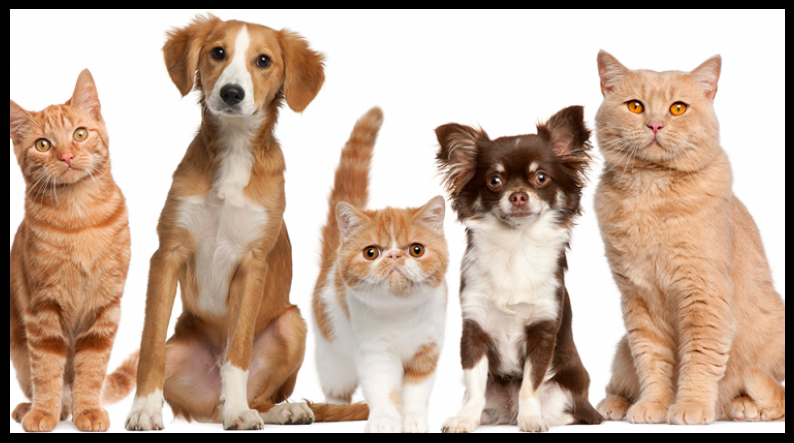

In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

import sys
sys.path.append("..")
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

image = cv2.imread('pets.png')  # Altere aqui a imagem a ser segmentada
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,10))
plt.imshow(image)
plt.axis('off')
plt.show()

In [7]:
sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

# Existem diversas configurações para o uso da biblioteca!
mask_generator_ = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.9,
    stability_score_thresh=0.96,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Requires open-cv to run post-processing
)

masks = mask_generator_.generate(image)

print(len(masks))

56


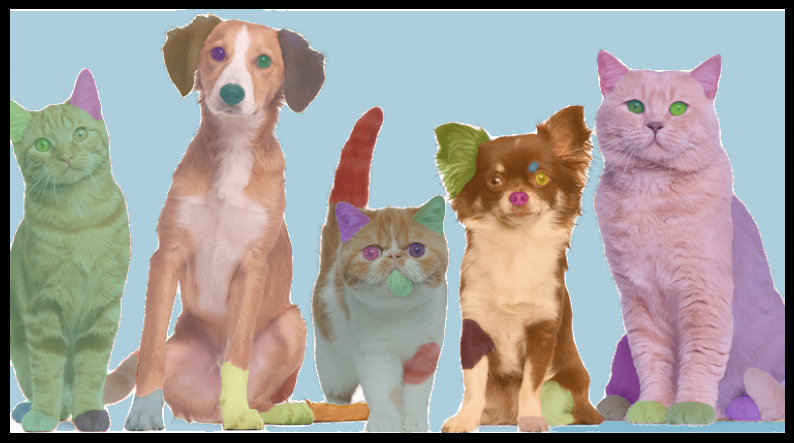

In [8]:
# Plotando tudo o que foi encontrado
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))

plt.figure(figsize=(10,10))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show()